The first tally-focused example. 

In [1]:
import openmc as omc
import numpy as np

# Material definitions
materials=omc.Materials()

m999 = omc.Material()
m999.add_nuclide('U238', 1.0)
m999.set_density('g/cc',7.0)
materials.append(m999)

In [2]:
# Surface definition
s1 = omc.Sphere(r=5)
s2 = omc.Sphere(r=6,boundary_type='vacuum')

# Cell definition
c10 = omc.Cell(fill=m999,region=-s1) 
c11 = omc.Cell(fill=None,region=+s1&-s2) 
c12 = omc.Cell(fill=None,region=+s2) 
geometry=omc.Geometry([c10,c11,c12])

This MCNP example features f1:n , and f4:n multiplied by fm4 102, which refer to neutron current over a surface, and neutron fluence multiplied by the neutron radiative capture cross section. Equivalent tallies are constructed here. 

In [3]:
# Tally creation
# To create a tally, we need to create a filter, which indicates what region in phase space
# can score to the tally.
f1_filter = omc.SurfaceFilter(bins=s1)
f1 = omc.Tally(name="f1",scores=['current'],filters=[f1_filter])

f4_filter = omc.CellFilter(bins=[c10])
f4 = omc.Tally(name="f4", scores=['(n,gamma)'],filters=[f4_filter])
tallies = omc.Tallies(tallies=[f1,f4])

The specification for the source below matches MCNP's SDEF, which is a 14 MeV isotropic source, sampled within the cell that contains the point (0,0,0). 

In [4]:
settings = omc.Settings()
settings.run_mode='fixed source'

# Source specification
source = omc.IndependentSource()
source.space = omc.stats.spherical_uniform(r_outer = 5, r_inner = 0) # the cell is spherical
source.angle = omc.stats.Isotropic() 
source.energy = omc.stats.delta_function(14e6) # energy in eV 
settings.source = source



To get good tally statistics, it is necessary to diverge somewhat from MCNP's run strategy specifications which are based on history-based statistics, and in this example calls for 2000 particle histories. We will still run the same number of particle histories, but split them into 20 batches of 100 particles each. 

In [5]:
model = omc.model.Model()
model.geometry = geometry
model.materials = materials
model.tallies = tallies

# OpenMC uses batch statistics, where each batch is a realization of the tally random variables. 
# This setting sets the number of particles per batch. So we actually need 2000 batches of 1 particle history
# each to match MCNP's default statistics. This is not optimal for a number of reasons, including that OpenMC
# uses history-based parallelism (so you want quite a few particles per batch for load balancing). 
settings.particles = 100
settings.batches = 20

model.settings=settings

In [6]:
w = 45
plots = omc.Plots()

plot = omc.SlicePlot()
plot.basis = 'xy'
plot.origin = (0.0, 0.0, 0.0)
plot.width = (w,w)
plot.pixels = (400, 400)
plot.color_by= 'cell'
#plot.level=level
plots.append(plot)

plot = omc.SlicePlot()
plot.basis = 'xz'
plot.origin = (0.0, 0.0, 0.0)
plot.width = (w,w)
plot.pixels = (400, 400)
plot.color_by= 'cell'
#plot.level=level
#plots.append(plot)

plot = omc.SlicePlot()
plot.basis = 'yz'
plot.origin = (0.0, 0.0, 0.0)
plot.width = (w,w)
plot.pixels = (400, 400)
plot.color_by= 'cell'
#plot.level = level
#plots.append(plot)

model.plots = plots

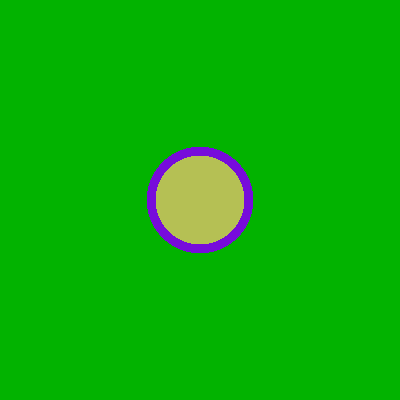

In [7]:
model.export_to_xml()
omc.plot_inline(plots)

Tally post-processing:

model.run() will return the resulting statepoint.h5 file that contains all of the results. 

In [8]:
sp_filename = model.run()

                                %%%%%%%%%%%%%%%
                           %%%%%%%%%%%%%%%%%%%%%%%%
                        %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                      %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                    %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                   %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                                    %%%%%%%%%%%%%%%%%%%%%%%%
                                     %%%%%%%%%%%%%%%%%%%%%%%%
                 ###############      %%%%%%%%%%%%%%%%%%%%%%%%
                ##################     %%%%%%%%%%%%%%%%%%%%%%%
                ###################     %%%%%%%%%%%%%%%%%%%%%%%
                ####################     %%%%%%%%%%%%%%%%%%%%%%
                #####################     %%%%%%%%%%%%%%%%%%%%%
                ######################     %%%%%%%%%%%%%%%%%%%%
                #######################     %%%%%%%%%%%%%%%%%%
                 #######################     %%%%%%%%%%%%%%%%%
                 #####################

In [10]:
# open the results file
with omc.StatePoint(sp_filename) as sp:

    # access the tally using pandas dataframes
    f1_tally = sp.get_tally(name='f1')
    df = f1_tally.get_pandas_dataframe()

    print(df)

    f4_tally = sp.get_tally(name='f4')
    df = f4_tally.get_pandas_dataframe()
    
    print(df)

   surface nuclide    score     mean  std. dev.
0        1   total  current 1.36e+00   2.41e-02
   cell nuclide      score     mean  std. dev.
0     1   total  (n,gamma) 3.53e-03   3.08e-04


/home/jovibuca/anaconda3/envs/omc/lib/python3.12/site-packages/uncertainties/core.py:1024: UserWarning: Using UFloat objects with std_dev==0 may give unexpected results.
  warn("Using UFloat objects with std_dev==0 may give unexpected results.")
